复习前6天学过的内容

In [2]:
#生成练习数据
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

dates = pd.date_range(
    start="2026-11-01",
    periods=20,
    freq="D"
)

data = []

for tool in ["Tool_A", "Tool_B"]:

    for i, date in enumerate(dates):

        if tool == "Tool_A":
            defect = np.random.normal(50, 2)
            light = np.random.normal(100, 1)
            focus = np.random.normal(0, 0.1)

        else:
            if i < 10:
                defect = np.random.normal(50, 2)
                light = np.random.normal(100, 1)
            else:
                defect = np.random.normal(
                    50 + (i - 9) * 2,
                    2
                )
                light = np.random.normal(
                    100 - (i - 9) * 1.5,
                    1
                )

            focus = np.random.normal(0, 0.1)

        # 添加一个明显的异常点
        if tool == "Tool_B" and i == 17:
            defect = 85

        data.append({
            "Date": date,
            "Tool_ID": tool,
            "Wafer_ID": f"{tool}_{i+1:03d}",
            "Defect_Count": round(defect),
            "Light_Intensity": round(light, 2),
            "Focus_Offset": round(focus, 3)
        })

df = pd.DataFrame(data)

df.to_csv("wafer_inspection.csv", index=False)

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             40 non-null     str    
 1   Tool_ID          40 non-null     str    
 2   Wafer_ID         40 non-null     str    
 3   Defect_Count     40 non-null     int64  
 4   Light_Intensity  40 non-null     float64
 5   Focus_Offset     40 non-null     float64
dtypes: float64(2), int64(1), str(3)
memory usage: 3.0 KB
         count  mean  median       std  min  max
Tool_ID                                         
Tool_A      20  50.1    50.0  1.447321   48   53
Tool_B      20  56.3    52.0  9.448475   48   85
        Defect_Count           Light_Intensity           Focus_Offset  \
                mean       std            mean       std         mean   
Tool_ID                                                                 
Tool_A          50.1  1.447321         99.7350  1.021488      -0.025

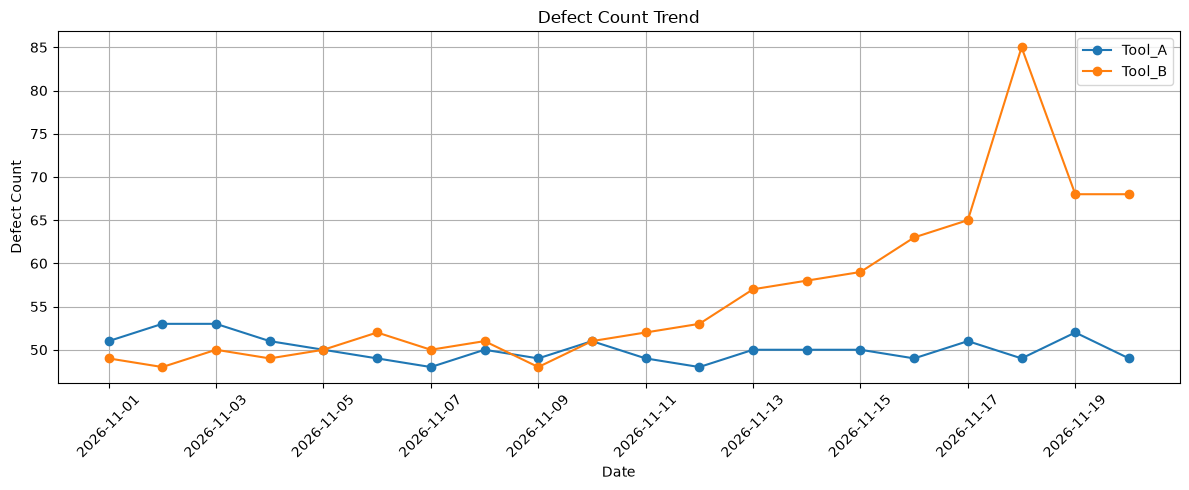

{'Tool_A': {'CL': np.float64(50.5), 'UCL': np.float64(55.44974746830583), 'LCL': np.float64(45.55025253169417)}, 'Tool_B': {'CL': np.float64(49.8), 'UCL': np.float64(53.749683531626296), 'LCL': np.float64(45.8503164683737)}}


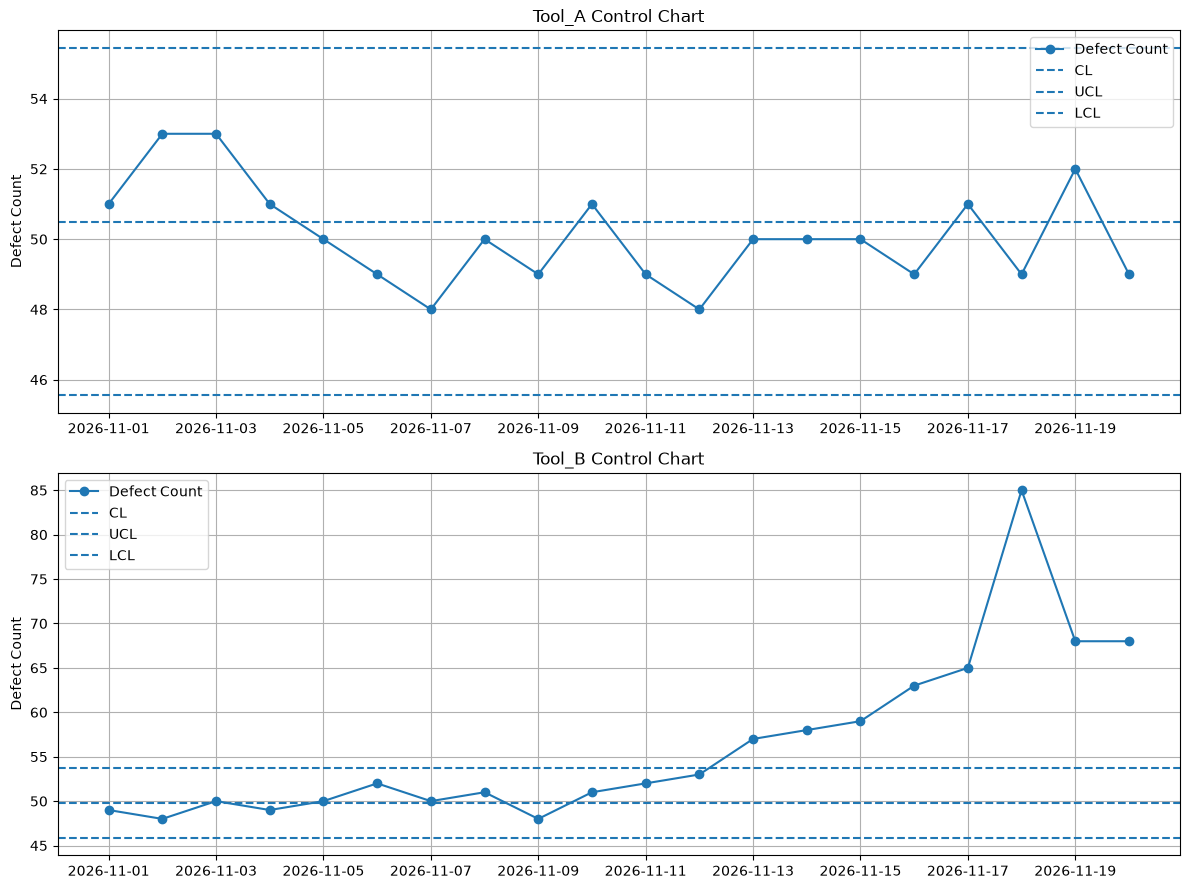

         Date Tool_ID    Wafer_ID  Defect_Count  Light_Intensity  \
32 2026-11-13  Tool_B  Tool_B_013            57            95.76   
33 2026-11-14  Tool_B  Tool_B_014            58            92.58   
34 2026-11-15  Tool_B  Tool_B_015            59            91.70   
35 2026-11-16  Tool_B  Tool_B_016            63            92.89   
36 2026-11-17  Tool_B  Tool_B_017            65            89.43   
37 2026-11-18  Tool_B  Tool_B_018            85            88.06   
38 2026-11-19  Tool_B  Tool_B_019            68            86.80   
39 2026-11-20  Tool_B  Tool_B_020            68            86.14   

    Focus_Offset        UCL        LCL    CL  Anomaly  
32         0.001  53.749684  45.850316  49.8     True  
33        -0.042  53.749684  45.850316  49.8     True  
34        -0.016  53.749684  45.850316  49.8     True  
35         0.017  53.749684  45.850316  49.8     True  
36        -0.192  53.749684  45.850316  49.8     True  
37         0.246  53.749684  45.850316  49.8     Tr

In [22]:
#导入Python库
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#第一步：读取数据
df = pd.read_csv("wafer_inspection.csv")

df.head() #默认显示前 5 行，帮助我们快速了解数据结构

#检查数据基本信息
df.info()

#查看数据的统计概况
df.describe()

#第二步：清洗数据
#检查缺失值
df.isnull().sum()
#如果发现缺失值，可以删除包含缺失值的整行
#df_clean = df.dropna() 
#也可以只删除特定列有缺失值的行
#df_clean = df.dropna(subset=["Temperature"])

#检查重复数据
df.duplicated().sum()
#如果发现重复记录，可以使用：
#df = df.drop_duplicates()

#检查数据类型
df.dtypes

#确保日期列是日期类型
df["Date"] = pd.to_datetime(df["Date"])

#确保数值列是数字类型。定义需要转换的列名列表：Defect_Count,Light_Intensity,Focus_Offset
numeric_cols = [   #创建一个名为 numeric_cols 的 Python 列表（List），里面装着你想要处理的三个列名：缺陷数量、光照强度、对焦偏移量
    "Defect_Count",
    "Light_Intensity",
    "Focus_Offset"
]

#开启循环：遍历刚才创建的列表。col 会在第一次循环时等于 "Defect_Count"，第二次等于 "Light_Intensity"，第三次等于 "Focus_Offset"
#调用 Pandas 的 to_numeric() 函数，尝试把当前循环到的这一列（比如 df["Defect_Count"]）的数据类型（dtype）强制转换为数字（整数或浮点数）。
#等号左边 df[col]：把转换成功的新数据，覆盖回原来的列
for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"  #如果遇到不能转换成数字的内容，就将其转换成 NaN。它的意思是“强制/胁迫”。
    )   #加上 errors="coerce" 后，Pandas 遇到能转成数字的（如 "12", "3.14"）就正常转；遇到不能转的乱七八糟的字符，它不报错，而是默默地把那个单元格变成 NaN（空值）。

#再次检查缺失值
df.isnull().sum()

#按日期和设备排序
df = df.sort_values(
    ["Tool_ID", "Date"]  #先按设备分组排序，再按日期排序
).reset_index(drop=True) #重新生成连续行索引，不保留旧索引

#第三步：按设备分组（Groupby）
#groupby("Tool_ID")：按照设备编号分组
#["Defect_Count"]：选择缺陷数量这一列
#.mean()：计算每台设备的平均缺陷数量
df.groupby("Tool_ID")["Defect_Count"].mean()

#一次性计算多个统计指标
summary = df.groupby("Tool_ID")["Defect_Count"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(summary)

#计算统计指标（Statistics）
parameter_summary = df.groupby("Tool_ID").agg(
    {
        "Defect_Count": ["mean", "std"],
        "Light_Intensity": ["mean", "std"],
        "Focus_Offset": ["mean", "std"]
    }
)

print(parameter_summary)

#绘制趋势图（Trend Chart）
plt.figure(figsize=(12, 5)) #建立一个画布，尺寸为12英寸宽，5英寸高

for tool in df["Tool_ID"].unique(): #遍历所有机台（核心循环）
#找出数据表中所有的唯一机台号（比如 Tool_1, Tool_2 等），然后逐个遍历。
#.unique() 会提取出 Tool_ID 列中不重复的值。循环执行时，tool 变量每次会代表一个不同的机台。

    tool_data = df[df["Tool_ID"] == tool] #df["Tool_ID"] == tool是一个判断条件，生成True/False(布尔索引)。意思是:"找出表格里，机台名字正好等于当前这个机台的那几行"。
                                          #df[布尔序列]是选择器
    plt.plot(
        tool_data["Date"],
        tool_data["Defect_Count"],
        marker="o",
        label=tool
    )

#设置图表元素
plt.title("Defect Count Trend")
plt.xlabel("Date")
plt.ylabel("Defect Count")
plt.legend()
plt.grid(True)

#日期标签防重叠处理
plt.xticks(rotation=45) #把 X 轴（日期）的标签逆时针旋转 45 度
plt.tight_layout() #自动调整子图参数，让标签、标题不被画布边缘裁切（尤其是刚刚旋转了 45 度的日期标签，很容易被切掉）
plt.show()

#建立基础控制图（Control Chart）（这里只有计算，还没有画图）
#计算 CL、UCL 和 LCL
control_limits = {} #创建一个空字典用于存储结果

for tool in df["Tool_ID"].unique(): #提取 df 中所有不重复的机台号（如 Tool_1, Tool_2），开始逐个循环。

    tool_data = df[df["Tool_ID"] == tool] #布尔索引过滤。把属于当前机台的所有数据单独抠出来，存进 tool_data

    baseline = tool_data.head(10) #取当前机台数据的前 10 行作为基线（Baseline）

    mean = baseline["Defect_Count"].mean() #计算均值

    std = baseline["Defect_Count"].std() #计算标准差

    ucl = mean + 3 * std #计算控制上下限（3σ 原则）

    lcl = mean - 3 * std #计算控制上下限（3σ 原则）

    control_limits[tool] = {   #存入字典:把算好的三个数字，包装成一个嵌套的字典，然后作为值，存进 control_limits 字典里
        "CL": mean,
        "UCL": ucl,
        "LCL": lcl
    }

print(control_limits)

#绘制两台设备的控制图
fig, axes = plt.subplots(  #创建多子图画布。plt.subplots(2, 1)：这是创建多张图的命令；axes：代表包含子图的数组
    2, 1,                  #2 代表行数（上下两排）；1 代表列数（只有一列）
    figsize=(12, 9)
)

for ax, tool in zip(      #zip() 函数：这是一个非常强大的工具，它把两个列表“拉链式”地拼在一起
    axes,
    df["Tool_ID"].unique() #第一轮循环：ax 拿到图1，tool 拿到 Tool_1；第二轮循环：ax 拿到图2，tool 拿到 Tool_2。
):

#准备数据和控制线
    tool_data = df[df["Tool_ID"] == tool]

    limits = control_limits[tool]

    cl = limits["CL"]
    ucl = limits["UCL"]
    lcl = limits["LCL"]

#在指定的子图上画图
    ax.plot(              #plt 指挥的是“全局画布”，而 ax 指挥的是“当前这个子图”。
        tool_data["Date"],
        tool_data["Defect_Count"],
        marker="o",
        label="Defect Count"
    )

#画三条控制线
    ax.axhline(
        cl,
        linestyle="--",
        label="CL"
    )

    ax.axhline(
        ucl,
        linestyle="--",
        label="UCL"
    )

    ax.axhline(
        lcl,
        linestyle="--",
        label="LCL"
    )

#设置子图的标题和标签
    ax.set_title(f"{tool} Control Chart")
    ax.set_ylabel("Defect Count")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

#标记异常点（Anomaly Detection），让 Python 自动识别超过控制限的数据
#计算每个数据点是否超限
df["UCL"] = df["Tool_ID"].map(         #为表格新增一列 UCL,map：它的作用是“搬运”。它会遍历 Tool_ID 这一列，每遇到一个机台，就用 lambda 去字典里查出它的 UCL，并一一对应地填到新列里。
    lambda x: control_limits[x]["UCL"] #lambda x：这是一个匿名函数，x 代表当前行的机台名（比如 "Tool_1"）。
)

df["LCL"] = df["Tool_ID"].map(
    lambda x: control_limits[x]["LCL"]
)

df["CL"] = df["Tool_ID"].map(
    lambda x: control_limits[x]["CL"]
)

#创建异常标记:布尔逻辑判断（找出异常）
df["Anomaly"] = (                 #新增一列 Anomaly（异常），里面只包含 True（异常）或 False（正常）
    (df["Defect_Count"] > df["UCL"]) |
    (df["Defect_Count"] < df["LCL"])
)

#提取异常数据
anomalies = df[df["Anomaly"]] #把刚才生成的 Anomaly 列（由 True/False 组成）直接丢进 df[] 里。Pandas 会像个筛子一样，只把标记为 True 的行留下来，存入新变量 anomalies 中

#外层的中括号：过滤行（筛选数据）。例如，anomalies[...] 告诉 Pandas：“请从 anomalies 里面挑数据”
#内层的中括号：列表（指定列名）
print(
    anomalies[
        [
            "Date",    #在这里明确列出了想要打印的列名（共7列）
            "Tool_ID",
            "Defect_Count",
            "Light_Intensity",
            "Focus_Offset",
            "UCL",
            "LCL"        
        ]
    ]
)

#print(anomalies) #打印全部列